# Marker correlations within cells, between cells and across images

The preprint reports correlations between metabolic markers within epithelial cells (Supp. Fig. S4b) and across images (Fig. 5h). Technical causes can produce such correlations at each level, but different causes act at different levels:
- Within a cell, the markers share the cut through the cell, the mask and any signal spilling in from neighbours.
- Between adjacent cells, they share spillover, through segmentation errors or through cells overlapping in the depth of the section.
- Between cells beyond a cell diameter, spillover no longer acts, and only causes that vary across a region of an image remain, biological such as hypoxia, or technical such as section thickness or staining.
- Across images, causes shared by a whole image act, such as fixation, antigen preservation or antibody penetration.

I compute the same correlation matrix at these four levels, in epithelial cells only. The nuclear channel, dsDNA and histone H3, and the membrane channel, Na/K-ATPase and HLA class I, serve as reference. They went through the same staining and preprocessing as the metabolic markers, and their biology is unrelated to metabolism, so a technical cause at a given level would raise or lower them too.

The distance ranges follow `spatial/KasumiColorectal.ipynb`, whose juxtaview reaches 40 pixels and whose paraview excludes cells within 40 pixels and reaches 120 pixels.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
from plotnine import *
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform
from mizani.bounds import squish

data_dir = "../../data/"
output_dir = data_dir + "technical_controls/"
figure_dir = "../../figures/technical_controls/"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

metabolic = ["CA9", "CD98", "CytC", "MCT1", "ASCT2", "LDH", "GS", "GLS", "ATP5A", "CS", "PKM2", "GLUT1", "ARG1", "CPT1A"]
reference = ["nuclei", "membrane"]
channels = metabolic + reference
channel_names = {**{m: m for m in metabolic}, "nuclei": "Nuclear signal", "membrane": "Membrane signal"}

pixel_size = 0.390625     # µm per pixel
# Distances between centroids, in pixels, of the juxtaview and paraview of KasumiColorectal.ipynb
rings = {"adjacent": (0, 40), "non-adjacent": (40, 120)}
min_pairs = 20            # cells, or pairs of cells, in an image

def scale_fill_correlation(name="", limits=(-1, 1)):
    return scale_fill_gradient2(low="#FC8D62", mid="white", high="#6291FC", midpoint=0, limits=limits, oob=squish, name=name)

def correlation_heatmap(matrix, order, file_name, x, y, fill="SCC"):
    plot_frame = matrix.rename(index=channel_names, columns=channel_names).stack().reset_index()
    plot_frame.columns = ["row", "column", "rho"]
    plot_frame["row"] = pd.Categorical(plot_frame["row"], categories=order[::-1])
    plot_frame["column"] = pd.Categorical(plot_frame["column"], categories=order)
    gp = (ggplot(plot_frame, aes(x="column", y="row", fill="rho"))
          + geom_tile()
          + geom_text(aes(label="rho"), format_string="{:.2f}", size=5)
          + scale_fill_correlation(fill)
          + labs(x=x, y=y)
          + theme_classic()
          + theme(figure_size=(7, 6.5), axis_text_x=element_text(angle=90)))
    gp.save(figure_dir + file_name, verbose=False)
    return gp

# Coarse cell types of the MuVI views, as in PrepareMuData.ipynb
coarse_of = {fine: coarse for coarse, fines in {
    "Other_immune_cell": ["APC", "B_cell", "Neutrophil", "Other_immune_cell"],
    "Fibroblast": ["CAF"],
    "Macrophage": ["CD163_Macrophage", "CD68_Macrophage"],
    "CD4_lymphocyte": ["CD4_Tcell", "T_reg_cell"],
    "Epithelial_cell": ["Cancer_cell"],
    "Endothelial_cell": ["Endothelial_cell"],
    "Monocyte": ["Monocyte"],
    "Cytotoxic_lymphocyte": ["NK_cell", "CD8_Tcell"],
}.items() for fine in fines}

## 1. Cells
The input is the cell table that `metabolism/MetabViz.ipynb` writes and `multicellular/PrepareMuData.ipynb` reads. The images are those of the MuVI input, selected as in `PrepareMuData.ipynb`: images with more than 20 epithelial cells, of normal colon or of a pT stage. The metabolic markers are transformed, while the nuclear and membrane channels are not, which does not matter for the rank correlations used throughout. Cell positions are the centroids of the masks.

In [2]:
cell_table = pd.read_csv(data_dir + "cell_table_with_types_stage.csv",
                         usecols=channels + ["fov", "consensus", "Stage", "centroid-0", "centroid-1", "area"], low_memory=False)
cell_table["cell type"] = cell_table.consensus.map(coarse_of)

# Images of the MuVI input, as in PrepareMuData.ipynb
epithelial_counts = cell_table[cell_table["cell type"] == "Epithelial_cell"].fov.value_counts()
stage = cell_table.groupby("fov").Stage.first()
images = [fov for fov in epithelial_counts.index[epithelial_counts > 20]
          if stage[fov] in ["Colon-no.", "pT1", "pT2", "pT3", "pT4"]]
cell_table = cell_table[cell_table.fov.isin(images) & cell_table["cell type"].notna()]
epithelial = cell_table[cell_table["cell type"] == "Epithelial_cell"]

diameter = 2 * np.sqrt(cell_table.area / np.pi) * pixel_size
print(f"{len(cell_table)} cells in {len(images)} images, {len(epithelial)} epithelial cells in {epithelial.fov.nunique()} images")
print(f"Median cell diameter {np.median(diameter):.1f} µm, 95th percentile {np.percentile(diameter, 95):.1f} µm")
for level, (low, high) in rings.items():
    print(f"{level.capitalize()} cells from {low * pixel_size:.1f} to {high * pixel_size:.1f} µm")

451047 cells in 423 images, 258426 epithelial cells in 423 images
Median cell diameter 8.9 µm, 95th percentile 13.6 µm
Adjacent cells from 0.0 to 15.6 µm
Non-adjacent cells from 15.6 to 46.9 µm


## 2. Correlations at four levels
Within images, I compute each correlation over pairs of observations in an image and take the median over images. Within cells, a pair is a cell with itself. Between cells, a pair is two epithelial cells of the same image whose centroids lie in the distance range of each other, and each pair enters in both orders. A cell enters as many pairs as it has epithelial cells in range, which weights cells in dense epithelium more, but every correlation of a matrix uses the same pairs. I keep the images with at least 20 cells or pairs. A shift shared by a whole image is constant within the image and adds nothing to these correlations.

Across images, I take the median of each channel over the epithelial cells of an image, with no minimum number of cells as in `PrepareMuData.ipynb`, and compute the correlation across images.

All correlations are Spearman correlations between each channel of the first and each channel of the second member of a pair.

In [3]:
def within_image_correlations(distance_range=None):
    # Median over images of the correlations between the channels of the first and of the second member of the pairs
    per_image = []
    for fov, g in epithelial.groupby("fov"):
        values = g[channels].values
        if distance_range is None:
            first, second = values, values
        else:
            xy = g[["centroid-0", "centroid-1"]].values
            pairs = cKDTree(xy).query_pairs(distance_range[1], output_type="ndarray")
            pairs = pairs[np.hypot(*(xy[pairs[:, 0]] - xy[pairs[:, 1]]).T) >= distance_range[0]]
            first = np.concatenate([values[pairs[:, 0]], values[pairs[:, 1]]])
            second = np.concatenate([values[pairs[:, 1]], values[pairs[:, 0]]])
        if len(first) >= min_pairs:
            per_image.append(spearmanr(first, second).statistic[:len(channels), len(channels):])
    print(f"{len(per_image)} images")
    return pd.DataFrame(np.median(np.stack(per_image), axis=0), index=channels, columns=channels)

levels = {"within cells": within_image_correlations()}
for level, distance_range in rings.items():
    levels[level] = within_image_correlations(distance_range)
image_medians = epithelial.groupby("fov")[channels].median()
levels["across images"] = image_medians.corr("spearman")
print(f"{len(image_medians)} images")
pd.concat(levels, names=["level", "channel"]).to_csv(output_dir + "epithelial_correlation_levels.csv")

423 images


415 images


422 images
423 images


The four heatmaps share one order of rows and columns, so the same tile can be compared across levels. The order comes from hierarchical clustering with average linkage, with one minus the correlation as distance, on the four matrices averaged together and with their transposes.

In [4]:
mean_matrix = np.mean([m.values + m.values.T for m in levels.values()], axis=0) / 2
distance = squareform(1 - mean_matrix, checks=False)
order = [channel_names[channels[i]] for i in leaves_list(optimal_leaf_ordering(linkage(distance, method="average"), distance))]

### Within cells

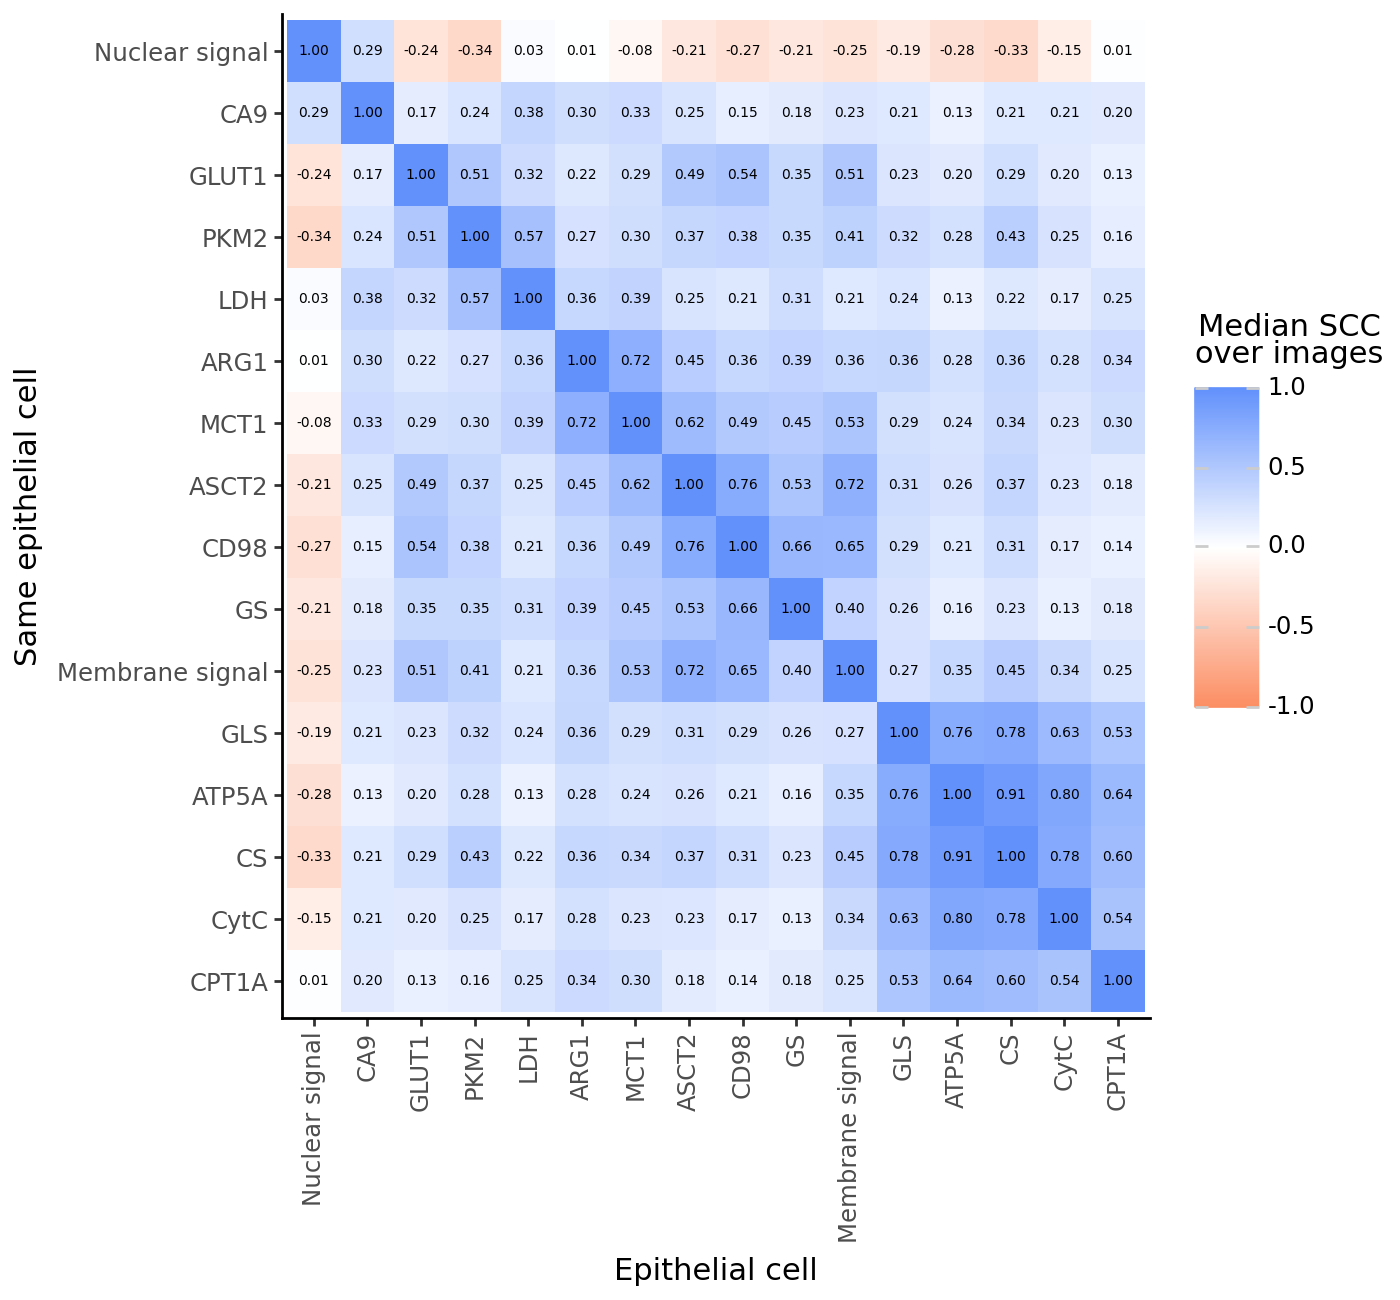

In [5]:
correlation_heatmap(levels["within cells"], order, "epithelial_correlation_within_cells.pdf",
                    x="Epithelial cell", y="Same epithelial cell", fill="Median SCC\nover images")

Within cells, the markers fall in three groups. The mitochondrial markers CytC, ATP5A, CS, GLS and CPT1A correlate strongly with each other and much less with the membrane signal. The membrane transporters ASCT2, CD98, GLUT1 and MCT1, with GS, correlate with each other and about as much with the membrane signal, which the cut through a cell and the share of membrane in the mask also produce. MCT1 and ARG1, and PKM2 and LDH, correlate with each other more than with the membrane signal. The nuclear signal correlates negatively with most markers, as expected when a mask that captures more nucleus captures less cytoplasm and membrane. CA9 is the exception, and correlates positively with the nuclear signal.

### Adjacent cells

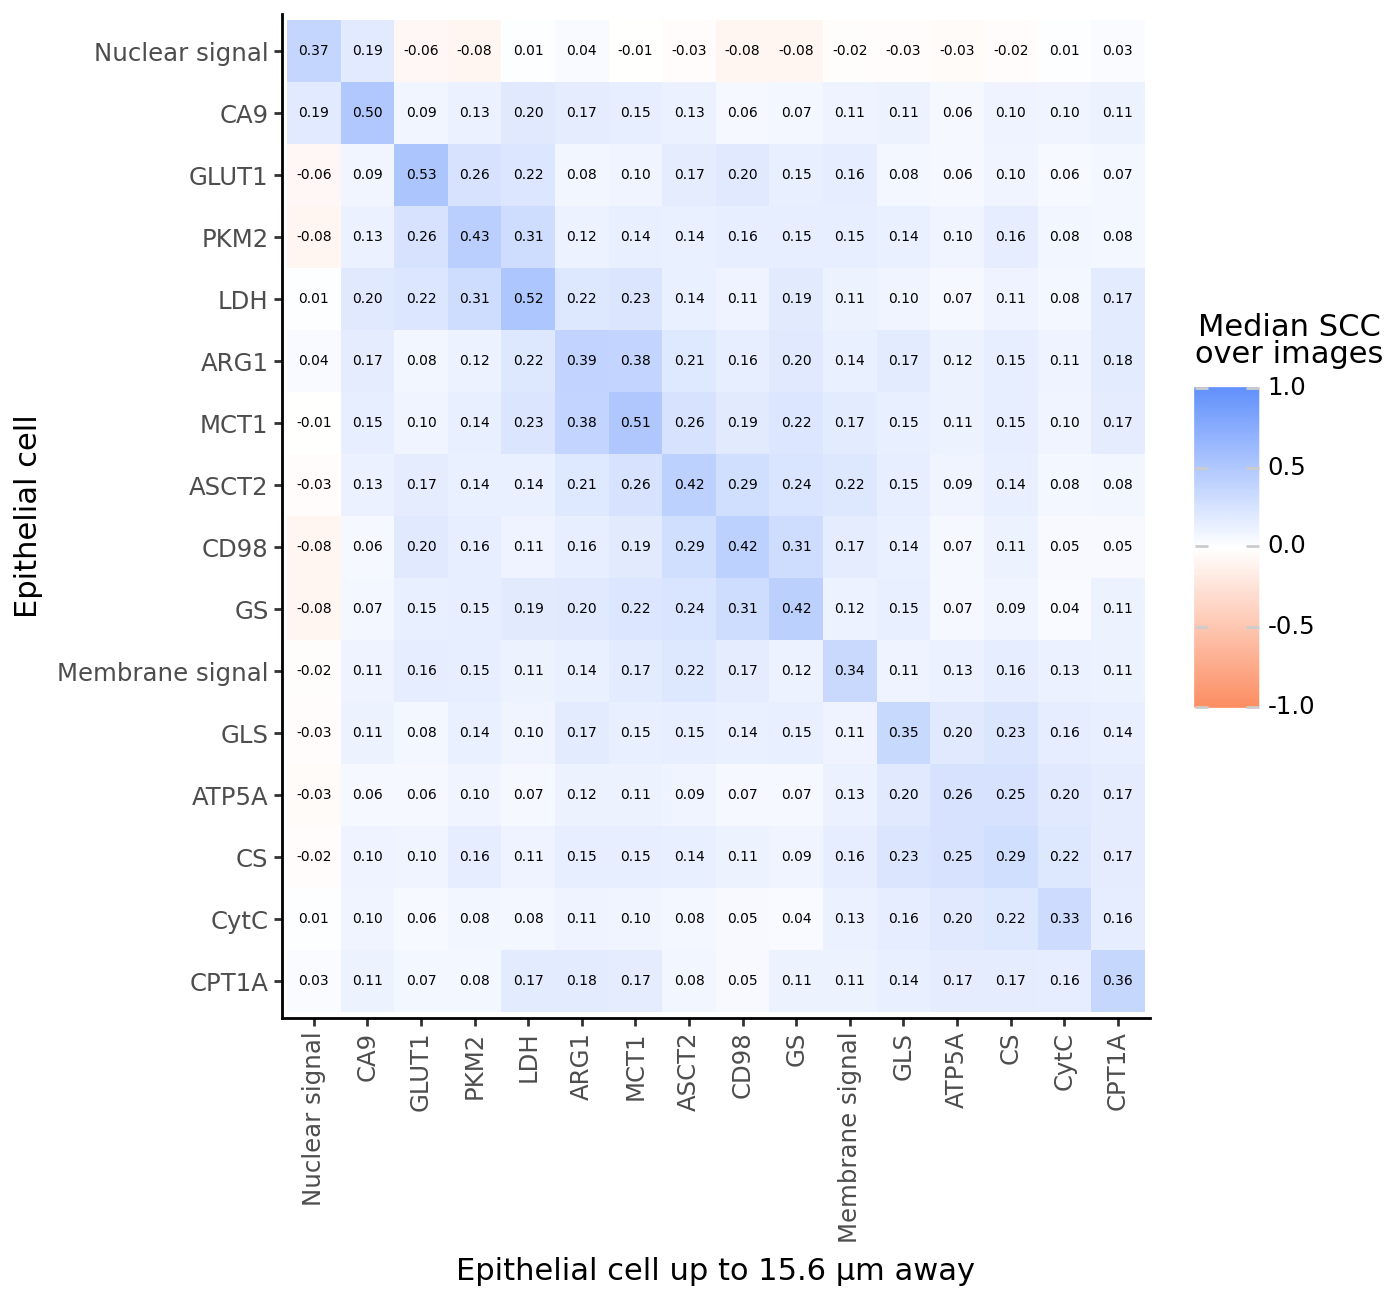

In [6]:
low, high = rings["adjacent"]
correlation_heatmap(levels["adjacent"], order, "epithelial_correlation_adjacent.pdf",
                    x=f"Epithelial cell up to {high * pixel_size:.1f} µm away", y="Epithelial cell",
                    fill="Median SCC\nover images")

Between adjacent cells, every channel correlates with itself, the reference channels included, and correlations between different markers are lower than within cells. The groups of the previous plot remain. Their correlations exceed those of the markers with the reference channels of the other cell, which stay low. The negative correlations with the nuclear signal disappear, since they come from the cut through a single cell. At this distance, spillover between touching cells can still add to every correlation.

### Non-adjacent cells

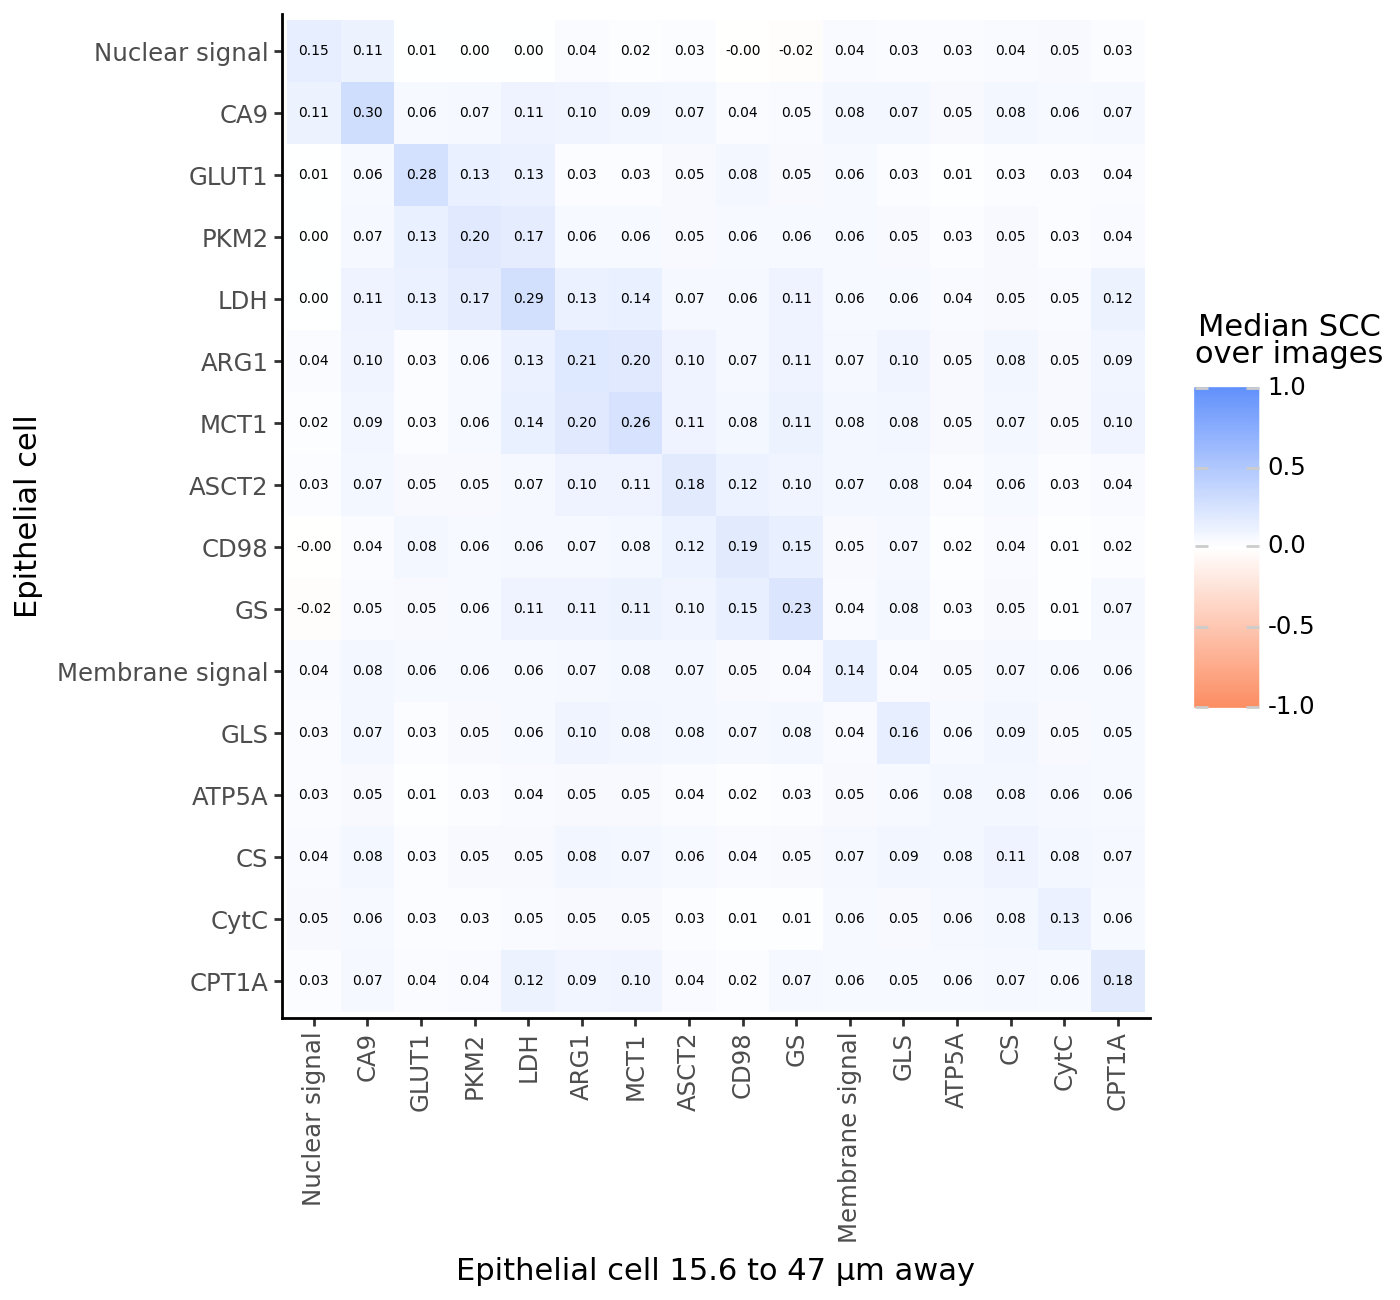

In [7]:
low, high = rings["non-adjacent"]
correlation_heatmap(levels["non-adjacent"], order, "epithelial_correlation_non_adjacent.pdf",
                    x=f"Epithelial cell {low * pixel_size:.1f} to {high * pixel_size:.0f} µm away", y="Epithelial cell",
                    fill="Median SCC\nover images")

Beyond spillover range, most metabolic markers still correlate with themselves more than the reference channels do, most of all CA9, LDH, GLUT1 and MCT1. The mitochondrial markers CytC, CS and ATP5A do not exceed the reference channels. The metabolic markers of a cell barely correlate with the membrane signal of the other cell, and not with its nuclear signal, except for CA9.

Three groups of different markers still correlate between cells: GLUT1, PKM2 and LDH, GS and CD98 with ASCT2, and MCT1 and ARG1, above the correlations of either marker with the reference channels of the other cell. The mitochondrial group, the strongest within cells, has faded to the level of the reference channels. Its coordination is a property of single cells that does not extend to the cells around.

### Across images

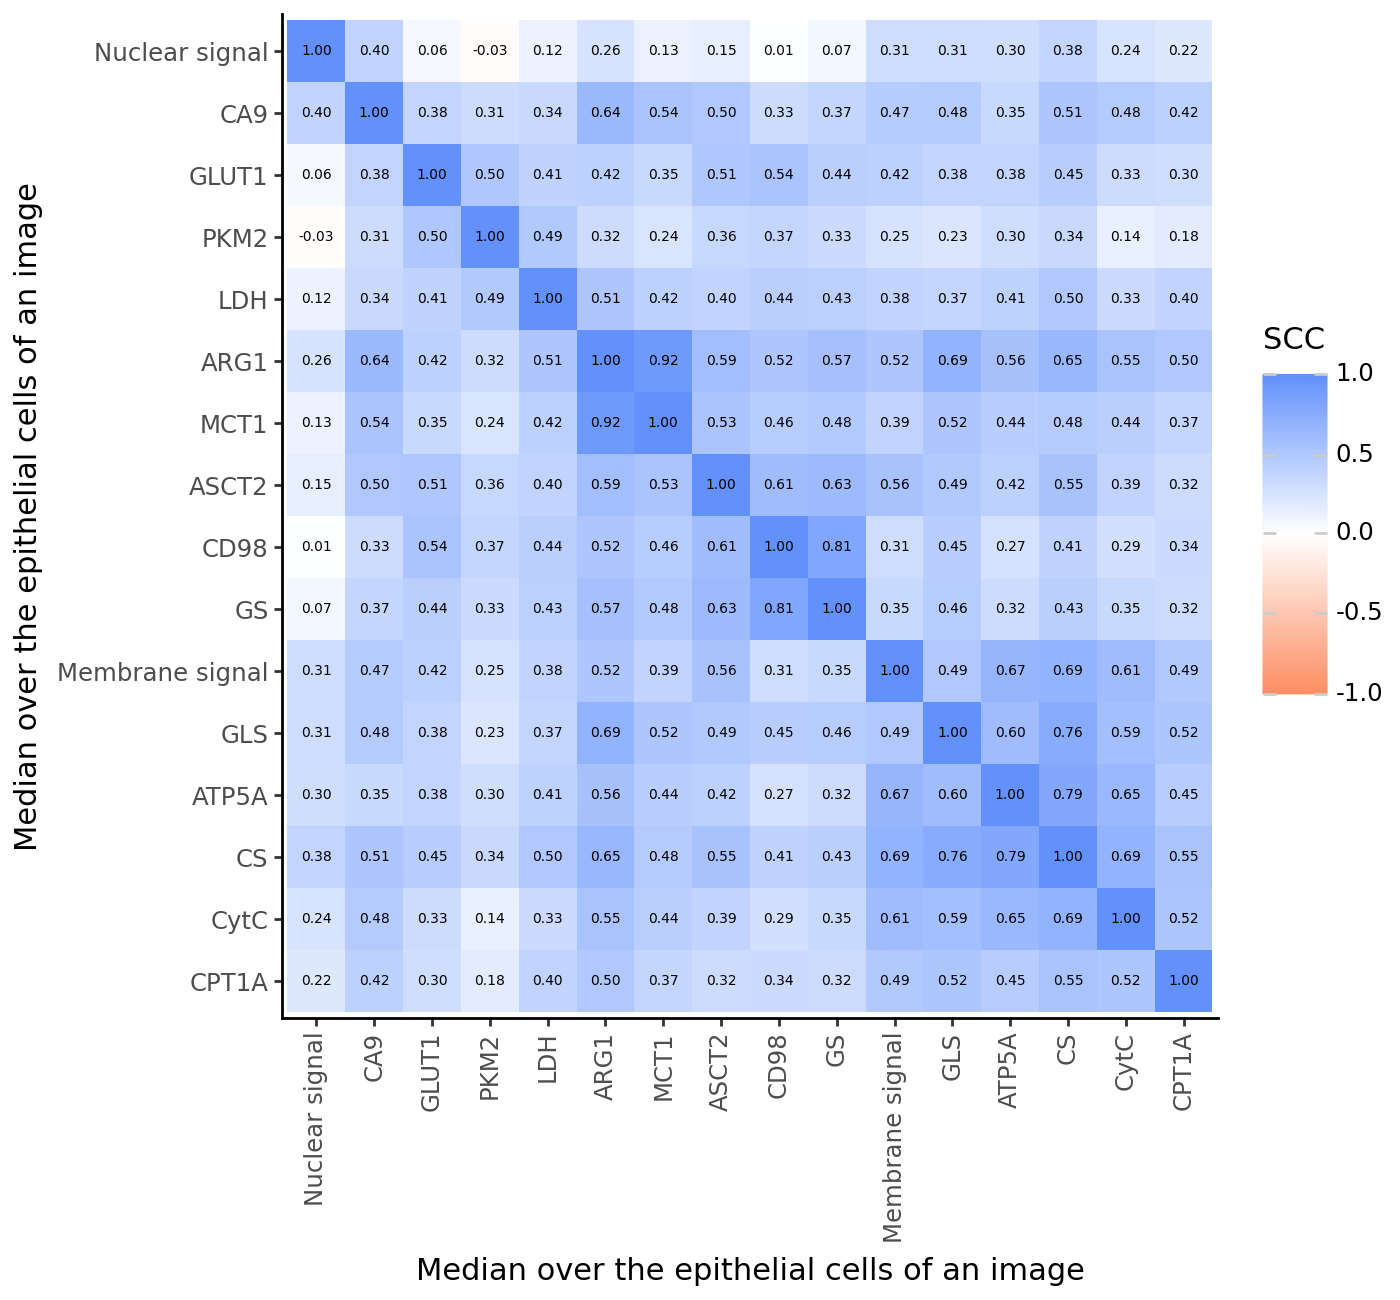

In [9]:
correlation_heatmap(levels["across images"], order, "epithelial_correlation_across_images.pdf",
                    x="Median over the epithelial cells of an image", y="Median over the epithelial cells of an image",
                    fill="SCC")

Across images, the reference channels correlate with most metabolic markers. The membrane signal correlates most with the mitochondrial markers CytC, ATP5A and CS, and clusters with them. The nuclear signal correlates less, most with CA9 and CS, and hardly with CD98, GS, PKM2 and GLUT1.

The groups of the previous levels return, and are stronger. MCT1 and ARG1, and GS and CD98 with ASCT2, are the most correlated pairs, far more than either marker correlates with the reference channels. GLUT1, PKM2 and LDH form a group that correlates less with the membrane channel and hardly with the nuclear channel. The mitochondrial markers correlate with each other about as much as with the membrane signal, so across images their correlation cannot be separated from the component they share with the membrane channel, unlike within cells. The other groups exceed it.